In [1]:
%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
import sys
sys.path.append('../../../python_modules/')
plt.rcParams['figure.dpi'] = 200
plt.rcParams['pdf.fonttype'] = '42'

from domino.models.domino_models import DominoSingleOutput
from domino.utils import tools
from domino.data.domino_data import GenomeDataset
from domino.data.data import preprocess_data
from domino.utils.tools import seq_from_df
import matplotlib.ticker as mticker
from generic_plotting_functions import *

import scipy.stats as stats
import pandas as pd
import os
import numpy as np

import fanc
import fanc.plotting as fancplot

from domino.utils.plotting import plot_attribution

import coolbox
from coolbox.api import *

# Larval brain

In [2]:
larval_model_dir = '/scratch/gpfs/PRITYKIN/brendan/domino/output/02_27_2026_final_larval_brain/DominoSingleOutput_10_16_2_1_200_32_False_False_42_0.001_plateau_5_1_512_5_256_5_4_64_gelu/'

larval_TRAIN_df = pd.read_csv(os.path.join(larval_model_dir, 'TRAIN_df.csv'))
larval_VAL_df = pd.read_csv(os.path.join(larval_model_dir, 'VAL_df.csv'))
larval_TEST_df = pd.read_csv(os.path.join(larval_model_dir, 'TEST_df.csv'))

adult_model_dir = '/scratch/gpfs/PRITYKIN/brendan/domino/output/06_13_2025_adult_brain/DominoSingleOutput_10_16_2_1_200_32_False_False_42_0.001_plateau_5_1_512_5_256_5_4_64_gelu/'

adult_TRAIN_df = pd.read_csv(os.path.join(adult_model_dir, 'TRAIN_df.csv'))
adult_VAL_df = pd.read_csv(os.path.join(adult_model_dir, 'VAL_df.csv'))
adult_TEST_df = pd.read_csv(os.path.join(adult_model_dir, 'TEST_df.csv'))

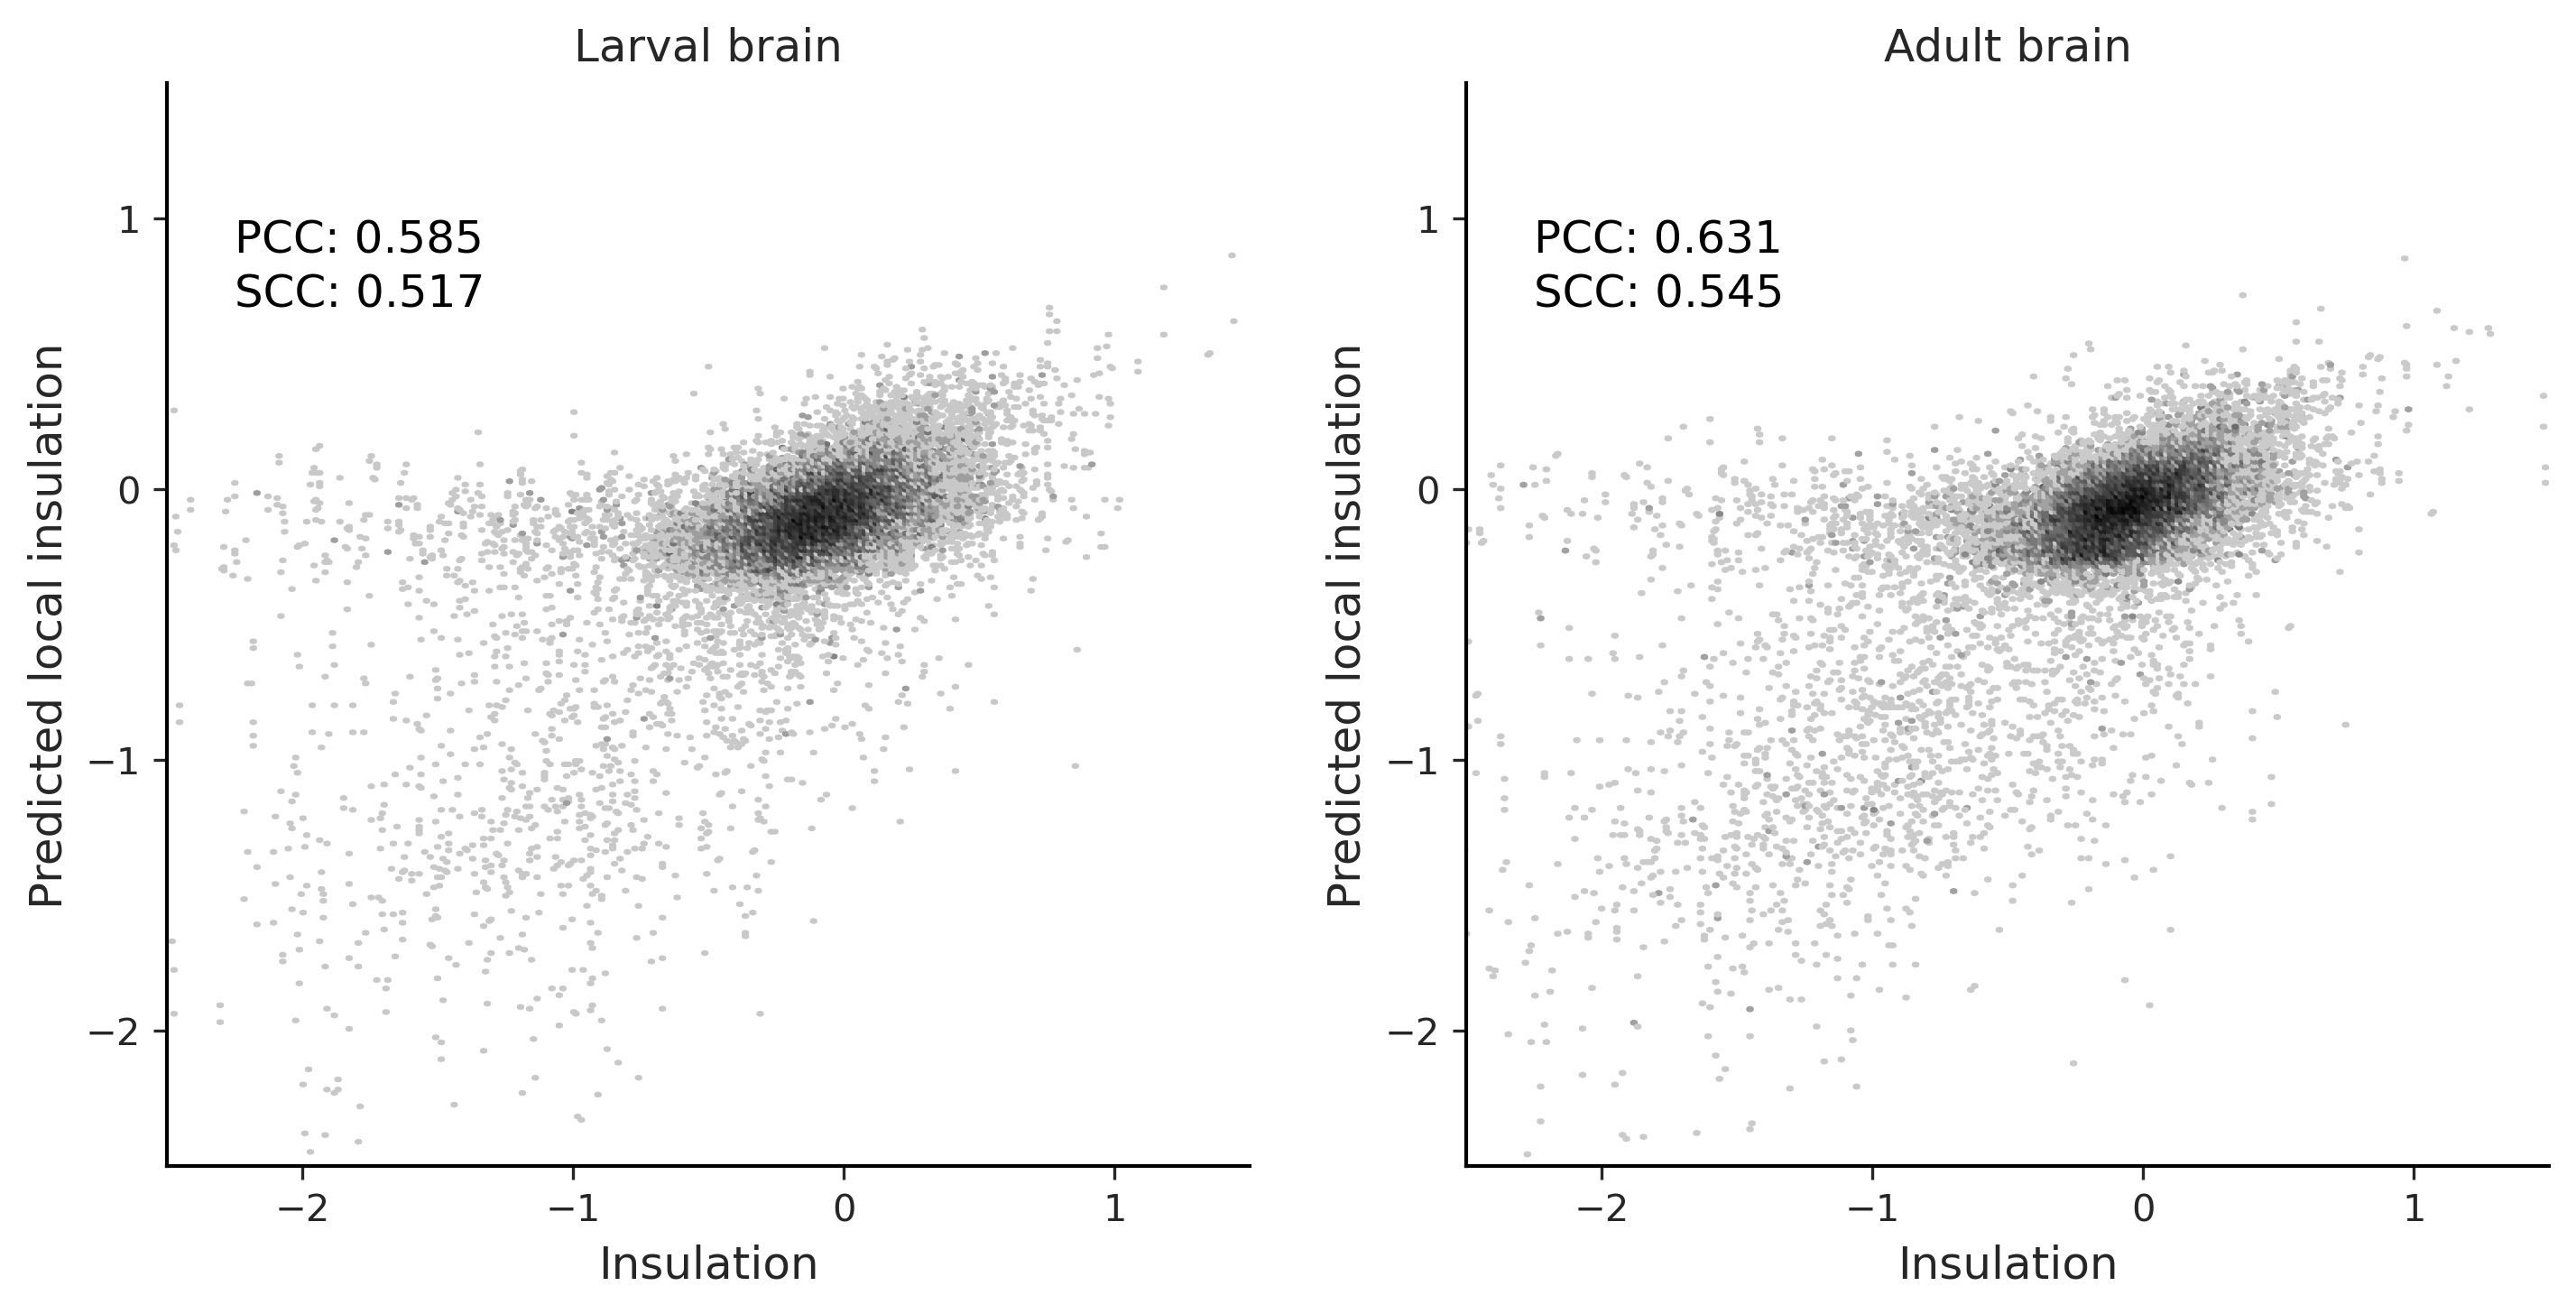

In [3]:
fig, axs = init_subplots_exact(2,1,dpi=300, sharex=True, sharey=True)

plt.sca(axs[0])
ax=axs[0]
X = larval_TEST_df
y_col='pred'

plt.hexbin(X['demeaned_ins_score_1'], X[y_col], gridsize=500, cmap='gray_r', bins='log', vmin=0.4)
max_val = X['demeaned_ins_score_1'].max()
min_val = X['demeaned_ins_score_1'].min()
plt.xlim(-2.5, 1.5)
plt.ylim(-2.5, 1.5)
plt.grid(False)
pearson = stats.pearsonr(X['demeaned_ins_score_1'], X[y_col])[0]
spearman = stats.spearmanr(X['demeaned_ins_score_1'], X[y_col])[0]
mse = np.mean((X['demeaned_ins_score_1'] - X[y_col]) ** 2)
plt.text(-2.25, 1, f'PCC: {pearson:.3f}',
 ha='left', va='top', fontsize=12, color='black')
plt.text(-2.25, 0.8, f'SCC: {spearman:.3f}',
     ha='left', va='top', fontsize=12, color='black')

ax.spines['top'].set_visible(False)     
ax.spines['right'].set_visible(False)   
ax.spines['left'].set_edgecolor('black')  
ax.spines['left'].set_linewidth(1)      
ax.spines['bottom'].set_edgecolor('black')
ax.spines['bottom'].set_linewidth(1)  
ax.yaxis.set_tick_params(left=True)   
ax.xaxis.set_tick_params(bottom=True) 

ax.xaxis.set_major_locator(mticker.MaxNLocator(integer=True))
ax.yaxis.set_major_locator(mticker.MaxNLocator(integer=True))

plt.ylabel('Predicted local insulation', fontsize=12)
plt.xlabel('Insulation', fontsize=12)
plt.title('Larval brain', fontsize=12)


plt.sca(axs[1])
ax=axs[1]
X = adult_TEST_df
y_col='pred'

plt.hexbin(X['demeaned_ins_score_1'], X[y_col], gridsize=500, cmap='gray_r', bins='log', vmin=0.4)
max_val = X['demeaned_ins_score_1'].max()
min_val = X['demeaned_ins_score_1'].min()
plt.xlim(-2.5, 1.5)
plt.ylim(-2.5, 1.5)
plt.grid(False)
pearson = stats.pearsonr(X['demeaned_ins_score_1'], X[y_col])[0]
spearman = stats.spearmanr(X['demeaned_ins_score_1'], X[y_col])[0]
mse = np.mean((X['demeaned_ins_score_1'] - X[y_col]) ** 2)
plt.text(-2.25, 1, f'PCC: {pearson:.3f}',
 ha='left', va='top', fontsize=12, color='black')
plt.text(-2.25, 0.8, f'SCC: {spearman:.3f}',
     ha='left', va='top', fontsize=12, color='black')

ax.spines['top'].set_visible(False)     
ax.spines['right'].set_visible(False)   
ax.spines['left'].set_edgecolor('black')  
ax.spines['left'].set_linewidth(1)      
ax.spines['bottom'].set_edgecolor('black')
ax.spines['bottom'].set_linewidth(1)  
ax.yaxis.set_tick_params(left=True)   
ax.xaxis.set_tick_params(bottom=True) 

ax.xaxis.set_major_locator(mticker.MaxNLocator(integer=True))
ax.yaxis.set_major_locator(mticker.MaxNLocator(integer=True))

plt.ylabel('Predicted local insulation', fontsize=12)
plt.xlabel('Insulation', fontsize=12)
plt.title('Adult brain', fontsize=12)

plt.show()

In [4]:
lb = -2.5
ub = 1.5

larval_perc = 100*len(larval_TEST_df.query('demeaned_ins_score_1 < @lb or demeaned_ins_score_1 > @ub or pred < @lb or pred > @ub'))/len(larval_TEST_df)
print('Larval percentage of points omitted', larval_perc)

adult_perc = 100*len(adult_TEST_df.query('demeaned_ins_score_1 < @lb or demeaned_ins_score_1 > @ub or pred < @lb or pred > @ub'))/len(adult_TEST_df)
print('Adult percentage of points omitted', adult_perc)

Larval percentage of points omitted 0.21128511061396968
Adult percentage of points omitted 0.19688139864545598
